# 6 · Testing on someone else's plant

The data-driven consistency checks on a toy plant (the HAI results need the dataset; see
`validation/results/hai_transfer.md`). See [Lesson 6](../docs/lessons/06-testing-on-someone-elses-plant.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fdicps import plotting
from fdicps.dual_anomaly_data_generation.parameters import load_sensor_parameters

plotting.use_style()
P = load_sensor_parameters()

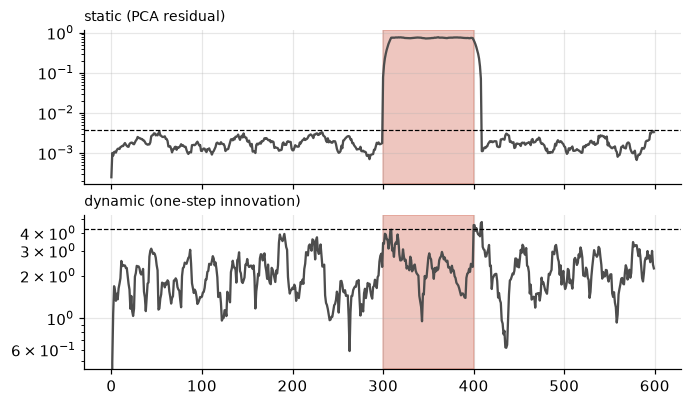

In [2]:
from fdicps.transfer.hai import DataDrivenConsistency

rng = np.random.default_rng(0)
mix = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [1.0, -1.0], [0.5, 2.0]])


def plant(n):
    latent = np.cumsum(rng.normal(size=(n, 2)) * 0.1, axis=0)
    return latent @ mix.T + rng.normal(size=(n, 5)) * 0.05


model = DataDrivenConsistency().fit(plant(4000))
test = plant(600)
test[300:400, 2] += 3.0
stats_ = model.statistics(test)
fig, axes = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
for ax, (name, s) in zip(axes, stats_.items()):
    ax.semilogy(s, color="0.3")
    ax.axhline(model.thresholds[name], color="k", ls="--", lw=0.8)
    ax.axvspan(300, 400, color=plotting.FDI_COLOR, alpha=0.3)
    ax.set_title(name, fontsize=9, loc="left")